# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Mã chính nằm trong `lab/` (`labels.py`, `vlm.py`, `run.py`, `viz.py`, `reward.py`). Mỗi lần huấn luyện/suy luận chạy trong **tiến trình riêng** (`!python -m lab.run …`) để VRAM đỉnh đo sạch và notebook không giữ bộ nhớ GPU.

## 0. Môi trường (Colab T4)

In [3]:
# Runtime → Change runtime type → T4 GPU
import os, sys, subprocess
from google.colab import drive
drive.mount("/content/drive")
REPO_URL = "https://github.com/nguyenducdong22/K4-Track-4-Day10-VisionLanguageModel"
REPO = "/content/K4-Track-4-Day10-VisionLanguageModel"
if not os.path.exists(REPO):
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO], check=True)
os.chdir(REPO); sys.path.insert(0, REPO)
SRC = "/content/drive/MyDrive/day10/lab_src.txt"   # bản mã lab/ khi chưa push lên GitHub
if not os.path.exists("lab/vlm.py") and os.path.exists(SRC):
    cur = None
    for line in open(SRC, encoding="utf-8").read().splitlines(True):
        if line.startswith("=====FILE: "):
            cur = line[11:].strip().rstrip("=").strip()
            os.makedirs(os.path.dirname(cur), exist_ok=True)
            open(cur, "w", encoding="utf-8").close()
        elif cur:
            open(cur, "a", encoding="utf-8").write(line)
    for d in ("lab", "lab/tests"):
        open(f"{d}/__init__.py", "a").close()
# Bản vá (sau khi upload lab_src.txt): transformers 5.19 không khớp "visual" trong llm_int8_skip_modules
_p = "lab/vlm.py"; _s = open(_p, encoding="utf-8").read()
if "def skip_modules" not in _s:
    _fn = '''def skip_modules(model_id=MODEL_ID):
    """Tên ĐẦY ĐỦ các Linear của ViT + projector để bitsandbytes KHÔNG lượng tử hoá.

    Với transformers 5.19, llm_int8_skip_modules=["visual", "lm_head"] chỉ khớp được lm_head:
    các Linear trong model.visual.* vẫn bị đổi thành Linear4bit (đã kiểm chứng: merger.linear_fc1
    là Linear4bit uint8, projector chỉ còn 54,6M "tham số" thay vì 109M). Vì vậy liệt kê tường minh.
    """
    from transformers import AutoConfig
    vc = AutoConfig.from_pretrained(model_id).vision_config
    names = ["visual", "lm_head"]
    for i in range(vc.depth):
        names += [f"model.visual.blocks.{i}.{s}"
                  for s in ("attn.qkv", "attn.proj", "mlp.linear_fc1", "mlp.linear_fc2")]
    names += ["model.visual.merger.linear_fc1", "model.visual.merger.linear_fc2"]
    for i in range(len(vc.deepstack_visual_indexes)):
        names += [f"model.visual.deepstack_merger_list.{i}.linear_fc{j}" for j in (1, 2)]
    return names


def load_model(model_id=MODEL_ID):'''
    _s = _s.replace('''                           llm_int8_skip_modules=["visual", "lm_head"])''',
                    '''                           llm_int8_skip_modules=skip_modules(model_id))''')
    _s = _s.replace("def load_model(model_id=MODEL_ID):", _fn, 1)
    open(_p, "w", encoding="utf-8").write(_s)
!md5sum lab/*.py lab/tests/*.py
!nvidia-smi -L
!pip -q install -r requirements-colab.txt kagglehub
# torchao 0.10 có sẵn trên Colab làm peft 0.21 báo lỗi khi gắn LoRA vào nn.Linear fp16 của ViT (E3)
!pip uninstall -y -q torchao

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
d41d8cd98f00b204e9800998ecf8427e  lab/__init__.py
e2829932a0c4eb299fe769bdf341da4b  lab/inspect_setup.py
f7a58cc92594f8b6f26c4abc73d7afa6  lab/labels.py
c3a14e4c23f2729ab641102cd3d690c6  lab/make_lab_notebook.py
2d8778ebd6082fd92de000a24ebc45fe  lab/reward.py
29f55383964ab9e15a370b14e0b6fc13  lab/run.py
3b3f7afe4e45df3eb35958aa42cb2bcd  lab/viz.py
d862451b41da5fd2561c76d68b526c97  lab/vlm.py
d41d8cd98f00b204e9800998ecf8427e  lab/tests/__init__.py
282e49a6166fde1e245ec9793135445b  lab/tests/test_lab.py
GPU 0: Tesla T4 (UUID: GPU-109d1846-55fe-90dd-108e-81ca3140c5a0)


In [4]:
# Lưu work/ (adapter, dự đoán) lên Google Drive để không mất khi session bị ngắt.
USE_DRIVE = True
if USE_DRIVE:
    os.makedirs("/content/drive/MyDrive/day10_work", exist_ok=True)
    if not os.path.islink("work"):
        !rm -rf work
        os.symlink("/content/drive/MyDrive/day10_work", "work")
!ls -la work/

total 211
drwx------  6 root root  4096 Oct 13 16:36 .
drwx------ 12 root root  4096 Oct 13 14:31 ..
-rw-------  1 root root 48217 Oct 13 09:48 e0.jsonl
drwx------  3 root root  4096 Oct 13 10:02 e1
-rw-------  1 root root 48517 Oct 13 14:38 e1.jsonl
drwx------  3 root root  4096 Oct 13 15:21 e2
-rw-------  1 root root 47121 Oct 13 16:24 e2.jsonl
drwx------  3 root root  4096 Oct 13 16:10 e3
-rw-------  1 root root 46195 Oct 13 16:35 e3.jsonl
drwx------  3 root root  4096 Oct 13 16:53 e4_data_size_0.1


In [5]:
# Kaggle: dùng Colab Secrets (KAGGLE_USERNAME, KAGGLE_KEY). KHÔNG viết khoá vào notebook.
import os
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    HAS_KAGGLE = True
except Exception as e:
    print("Không có Colab Secrets Kaggle → tải công khai bằng kagglehub:", type(e).__name__)
    HAS_KAGGLE = False

Không có Colab Secrets Kaggle → tải công khai bằng kagglehub: SecretNotFoundError


## 1. Dữ liệu: tải và chia split

In [6]:
if not os.path.exists("data/splits/meta.json"):
    if HAS_KAGGLE:
        !python scripts/prepare_data.py --kaggle
    else:
        import kagglehub
        src = kagglehub.dataset_download("lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes")
        !python scripts/prepare_data.py --source "{src}"
!python -m pytest -q

Using Colab cache for faster access to the 'road-damage-dataset-potholes-cracks-and-manholes' dataset.
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.33s


dataset_version: d10-21e4070301
train ảnh=1422 phiên= 13 box={'manhole': 691, 'pothole': 1074, 'crack': 1750} ảnh rỗng=0
val   ảnh= 276 phiên=  2 box={'crack': 470, 'manhole': 103, 'pothole': 66} ảnh rỗng=0
test  ảnh= 311 phiên=  3 box={'crack': 299, 'manhole': 163, 'pothole': 121} ảnh rỗng=0
OK: không phiên nào xuất hiện ở hai split
diện tích box trung vị (% khung hình): 0.74


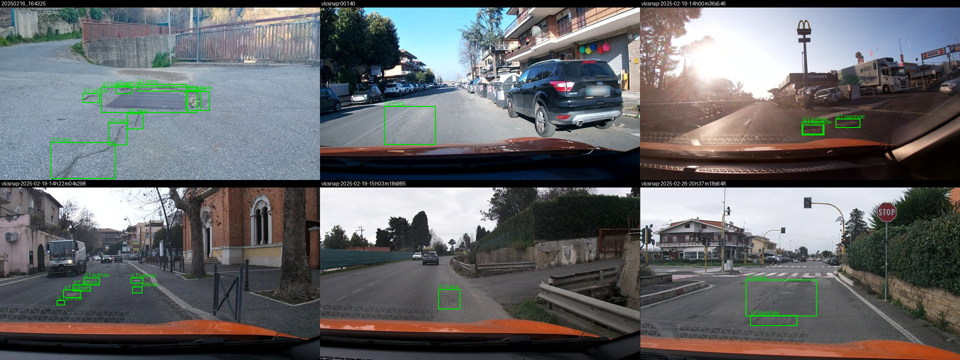

In [5]:
# Khám phá dữ liệu: số ảnh/box từng split, kiểm tra không phiên nào nằm ở 2 split, vẽ 6 ảnh có box
import json, collections
from lab.vlm import read_split
from lab.viz import draw
from PIL import Image
meta = json.load(open("data/splits/meta.json"))
print("dataset_version:", meta["dataset_version"])
splits = {s: read_split(s) for s in ("train", "val", "test")}
sess = {s: {e["session"] for e in v} for s, v in splits.items()}
for s, v in splits.items():
    c = collections.Counter(o["label"] for e in v for o in e["objects"])
    print(f"{s:5s} ảnh={len(v):4d} phiên={len(sess[s]):3d} box={dict(c)} ảnh rỗng={sum(not e['objects'] for e in v)}")
assert not (sess["train"] & sess["val"]) and not (sess["train"] & sess["test"]) and not (sess["val"] & sess["test"])
print("OK: không phiên nào xuất hiện ở hai split")
areas = sorted(o["yolo"][2] * o["yolo"][3] for v in splits.values() for e in v for o in e["objects"])
print("diện tích box trung vị (% khung hình):", round(100 * areas[len(areas) // 2], 2))
tiles = [draw(e, title=e["image_id"]) for e in splits["train"][::240][:6]]
grid = Image.new("RGB", (640 * 3, 360 * 2))
for k, im in enumerate(tiles):
    grid.paste(im, ((k % 3) * 640, (k // 3) * 360))
os.makedirs("report/figures", exist_ok=True)
grid.save("report/figures/data_samples.jpg", quality=85)
grid.resize((960, 360))

## 2. Nhãn: YOLO → JSON thang 0–1000

In [6]:
from lab.labels import yolo_to_box, objects_to_answer, box_to_pixel, get_prompt
e = splits["train"][0]
print(e["objects"])
ans = objects_to_answer(e["objects"])
print("answer:", ans)
print("prompt:", get_prompt())
# Kiểm tra quay ngược: 0–1000 → pixel phải trùng box YOLO gốc (sai số làm tròn ≤ 0,64 px)
for o, b in zip(sorted(e["objects"], key=lambda o: (o["yolo"][1] - o["yolo"][3] / 2)), json.loads(ans)):
    xc, yc, w, h = o["yolo"]
    gt_px = ((xc - w / 2) * 640, (yc - h / 2) * 360, (xc + w / 2) * 640, (yc + h / 2) * 360)
    back = box_to_pixel(b["bbox_2d"], "norm1000", 640, 360)
    print(b["label"], [round(v, 1) for v in gt_px], "→", [round(v, 1) for v in back])
!python -m pytest -q lab/tests

[{'label': 'manhole', 'yolo': [0.466407, 0.552778, 0.298437, 0.144444]}, {'label': 'pothole', 'yolo': [0.604688, 0.556944, 0.043751, 0.113889]}, {'label': 'pothole', 'yolo': [0.285156, 0.544444, 0.051562, 0.055555]}, {'label': 'pothole', 'yolo': [0.3875, 0.498611, 0.053124, 0.047222]}, {'label': 'crack', 'yolo': [0.421875, 0.672222, 0.05, 0.088889]}, {'label': 'crack', 'yolo': [0.259375, 0.891666, 0.203126, 0.205555]}, {'label': 'crack', 'yolo': [0.36875, 0.745833, 0.059376, 0.125]}, {'label': 'crack', 'yolo': [0.617188, 0.561111, 0.074999, 0.105556]}, {'label': 'crack', 'yolo': [0.50625, 0.486112, 0.153124, 0.038889]}]
answer: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,6

## 3. E0: zero-shot

In [14]:
!python -m lab.run infer --out work/e0.jsonl --split test

Loading weights: 100% 713/713 [00:27<00:00, 26.02it/s] 
infer 311 ảnh (đã có 0)
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
  8/311  0.1 min
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
  48/311  0.6 min
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[tran

In [6]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.923 P=0.131 R=0.074 F1=0.095 CI95=0.066-0.127 meanIoU=0.598 FP/img=0.91
   pothole  P=0.303 R=0.083 F1=0.130
   crack    P=0.038 R=0.027 F1=0.031
   manhole  P=0.305 R=0.153 F1=0.204


In [16]:
from scripts.score import parse_output
rows = [json.loads(l) for l in open("work/e0.jsonl")]
for r in rows[:5]:
    print(r["image_id"], "→", repr(r["raw"][:300]), "| parse:", parse_output(r["raw"]) is not None)

vlcsnap-00200 → '[{"label": "manhole", "bbox_2d": [759, 640, 843, 687]}]' | parse: True
vlcsnap-00201 → '[{"label": "crack", "bbox_2d": [0, 476, 1000, 999]}]' | parse: True
vlcsnap-00202 → '[{"label": "manhole", "bbox_2d": [309, 686, 399, 714]}]' | parse: True
vlcsnap-00203 → '[{"label": "crack", "bbox_2d": [0, 476, 1000, 998]}]' | parse: True
vlcsnap-00204 → '[{"label": "manhole", "bbox_2d": [257, 624, 325, 654]}]' | parse: True


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [17]:
# encode_example() và make_collate() nằm trong lab/vlm.py.
# Kiểm tra (tiến trình riêng): 220 token ảnh, phần có loss == JSON đáp án + <|im_end|>,
# 252/348 module LoRA, số tham số từng khối và tham số huấn luyện E1/E2/E3.
!python -m lab.inspect_setup

Loading weights: 100% 713/713 [00:30<00:00, 23.75it/s]
Tham số theo khối: {
 "visual.blocks(ViT)": 306242560,
 "projector": 109105152,
 "language_model+embed": 4022468096,
 "lm_head": 0,
 "other": 0,
 "total": 4437815808
}
keys: ['input_ids', 'attention_mask', 'mm_token_type_ids', 'pixel_values', 'image_grid_thw', 'labels']
image_grid_thw: [[1, 22, 40]]  số token ảnh: 220
seq len: 587  token có loss: 249
đáp án      : [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]
phần học    : '[{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,62

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [18]:
# apply_setup(model, targets, train_projector) trong lab/vlm.py:
#   - đóng băng mọi tham số, enable_input_require_grads()
#   - LoRA r=16 α=32 trên regex LLM (252 module) [+ ViT blocks (96) cho E3]
#   - E2/E3: visual.merger + visual.deepstack_merger_list → float32, requires_grad=True
print(json.dumps(json.load(open("report/setup_check.json")), indent=1, ensure_ascii=False)[:2500])

{
 "param_groups": {
  "visual.blocks(ViT)": 306242560,
  "projector": 109105152,
  "language_model+embed": 4022468096,
  "lm_head": 0,
  "other": 0,
  "total": 4437815808
 },
 "image_tokens": 220,
 "learned_text": "[{\"label\":\"crack\",\"bbox_2d\":[430,467,583,506]},{\"label\":\"pothole\",\"bbox_2d\":[361,475,414,522]},{\"label\":\"manhole\",\"bbox_2d\":[317,481,616,625]},{\"label\":\"pothole\",\"bbox_2d\":[583,500,627,614]},{\"label\":\"crack\",\"bbox_2d\":[580,508,655,614]},{\"label\":\"pothole\",\"bbox_2d\":[259,517,311,572]},{\"label\":\"crack\",\"bbox_2d\":[397,628,447,717]},{\"label\":\"crack\",\"bbox_2d\":[339,683,398,808]},{\"label\":\"crack\",\"bbox_2d\":[158,789,361,994]}]<|im_end|>",
 "lora_modules_llm": 252,
 "lora_modules_llm_vit": 348,
 "projector_params": 109105152,
 "trainable_e1": 33030144,
 "trainable_e2": 142135296,
 "trainable_e3": 148426752
}


## 6. Vòng huấn luyện

In [12]:
# Chạy thử nhanh (2 bước trên val, suy luận 8 ảnh) để bắt lỗi trước khi tốn 30 phút
!python -m lab.run train --exp e2 --out work/smoke --split val --max-steps 2
!python -m lab.run infer --ckpt work/smoke --out work/smoke.jsonl --split val --limit 8
!rm -rf work/smoke work/smoke.jsonl

Loading weights: 100% 713/713 [00:29<00:00, 24.40it/s]
LoRA target modules: 252  (vd model.language_model.layers.0.self_attn.q_proj … model.language_model.layers.35.mlp.down_proj)
trainable params: 142,135,296  (LoRA 33,030,144 + projector 109,105,152)
train images: 276
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step    1/2 loss 1.9378 lr 2.00e-04 gn 5.55 0.8 min vram 6.22 GB
{
  "trainable_params": 142135296,
  "lora_params": 33030144,
  "projector_params": 109105152,
  "n_lora_modules": 252,
  "peak_vram_gb": 7.27,
  "train_minutes": 0.9,
  "steps": 2,
  "train_images": 276,
  "train_fraction": 1.0,
  "coord": "norm1000"
}
Loading weights: 100% 713/713 [00:27<00:00, 25.71it/s] 
đã nạp lại 24 tensor projector
infer 8 ảnh (đã có 0)
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
  8/8  0.8 min
xong infer: 0.8 min


In [19]:
# AdamW lr 2e-4, warmup 5% + cosine, fp16 autocast + GradScaler, batch 2 × accum 4, 300 bước,
# gradient checkpointing, lưu adapter (+ projector.pt cho E2/E3) mỗi 100 bước, ghi run.json.
!python -m lab.run train --exp e1 --out work/e1

Loading weights: 100% 713/713 [00:32<00:00, 21.94it/s]
LoRA target modules: 252  (vd model.language_model.layers.0.self_attn.q_proj … model.language_model.layers.35.mlp.down_proj)
trainable params: 33,030,144  (LoRA 33,030,144 + projector 0)
train images: 1422
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step    1/300 loss 2.2063 lr 1.33e-05 gn 6.48 0.8 min vram 5.33 GB
step   10/300 loss 0.8031 lr 1.33e-04 gn 0.73 1.9 min vram 5.70 GB
step   20/300 loss 0.7532 lr 2.00e-04 gn 0.48 3.3 min vram 6.44 GB
step   30/300 loss 0.6732 lr 1.99e-04 gn 0.55 4.8 min vram 6.44 GB
step   40/300 loss 0.6194 lr 1.96e-04 gn 0.41 6.2 min vram 6.44 GB
step   50/300 loss 0.6271 lr 1.93e-04 gn 0.47 7.7 min vram 6.44 GB
step   60/300 loss 0.6356 lr 1.88e-04 gn 0.45 9.1 min vram 6.44 GB
step   70/300 loss 0.6381 lr 1.82e-04 gn 0.41 10.6 min vram 6.44 GB
step   80/300 loss 0.5988 lr 1.75e-04 gn 0.59 12.1 min vram 6.44 GB
step   90/300 loss 0.6413 lr 1

In [8]:
!python -m lab.run train --exp e2 --out work/e2

Loading weights: 100% 713/713 [00:35<00:00, 20.32it/s]
LoRA target modules: 252  (vd model.language_model.layers.0.self_attn.q_proj … model.language_model.layers.35.mlp.down_proj)
trainable params: 142,135,296  (LoRA 33,030,144 + projector 109,105,152)
train images: 1422
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step    1/300 loss 2.2063 lr 1.33e-05 gn 7.07 0.8 min vram 6.21 GB
step   10/300 loss 0.8092 lr 1.33e-04 gn 1.31 2.0 min vram 7.39 GB
step   20/300 loss 0.7413 lr 2.00e-04 gn 1.08 3.4 min vram 8.14 GB
step   30/300 loss 0.6695 lr 1.99e-04 gn 0.67 4.7 min vram 8.14 GB
step   40/300 loss 0.6024 lr 1.96e-04 gn 0.42 6.0 min vram 8.14 GB
step   50/300 loss 0.6275 lr 1.93e-04 gn 0.58 7.3 min vram 8.14 GB
step   60/300 loss 0.6280 lr 1.88e-04 gn 0.49 8.7 min vram 8.14 GB
step   70/300 loss 0.6676 lr 1.82e-04 gn 0.66 10.0 min vram 8.14 GB
step   80/300 loss 0.5837 lr 1.75e-04 gn 0.56 11.3 min vram 8.14 GB
step   90/300 loss 

In [9]:
!python -m lab.run train --exp e3 --out work/e3

Loading weights: 100% 713/713 [00:35<00:00, 20.11it/s]
LoRA target modules: 348  (vd model.visual.blocks.0.attn.qkv … model.language_model.layers.35.mlp.down_proj)
trainable params: 148,426,752  (LoRA 39,321,600 + projector 109,105,152)
train images: 1422
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step    1/300 loss 2.2063 lr 1.33e-05 gn 7.81 0.9 min vram 6.34 GB
step   10/300 loss 0.7967 lr 1.33e-04 gn 1.84 2.3 min vram 7.57 GB
step   20/300 loss 0.7426 lr 2.00e-04 gn 0.85 3.9 min vram 8.31 GB
step   30/300 loss 0.6290 lr 1.99e-04 gn 0.77 5.5 min vram 8.31 GB
step   40/300 loss 0.5577 lr 1.96e-04 gn 0.89 7.1 min vram 8.31 GB
step   50/300 loss 0.5901 lr 1.93e-04 gn 0.94 8.7 min vram 8.31 GB
step   60/300 loss 0.5714 lr 1.88e-04 gn 0.91 10.3 min vram 8.31 GB
step   70/300 loss 0.6376 lr 1.82e-04 gn 1.03 11.9 min vram 8.31 GB
step   80/300 loss 0.5593 lr 1.75e-04 gn 2.31 13.5 min vram 8.31 GB
step   90/300 loss 0.5986 lr 1.68e

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 4))
for k in ("e1", "e2", "e3", "e4_data_size_0.1"):
    p = f"work/{k}/train_log.json"
    if os.path.exists(p):
        log = json.load(open(p))
        ys = [r["loss"] for r in log]
        sm = [sum(ys[max(0, i - 9):i + 1]) / len(ys[max(0, i - 9):i + 1]) for i in range(len(ys))]
        plt.plot([r["step"] for r in log], sm, label=k)
plt.xlabel("bước"); plt.ylabel("loss (TB trượt 10)"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("report/figures/loss_curves.png", dpi=110, bbox_inches="tight"); plt.show()

NameError: name 'json' is not defined

<Figure size 800x400 with 0 Axes>

## 7. Suy luận và chấm E1–E3

In [10]:
for k in ("e1", "e2", "e3"):
    !python -m lab.run infer --ckpt work/{k} --out work/{k}.jsonl --split test
    !python -m lab.run score --name {k.upper()} --pred work/{k}.jsonl --run work/{k}/run.json --out report/evidence/{k}.json

Loading weights: 100% 713/713 [00:43<00:00, 16.42it/s]
infer 0 ảnh (đã có 311)
xong infer: 0.0 min
E1 [test] n=311 valid=0.994 P=0.287 R=0.273 F1=0.280 CI95=0.241-0.320 meanIoU=0.677 FP/img=1.27
   pothole  P=0.210 R=0.140 F1=0.168
   crack    P=0.192 R=0.244 F1=0.215
   manhole  P=0.750 R=0.423 F1=0.541
Loading weights: 100% 713/713 [00:36<00:00, 19.48it/s]
đã nạp lại 24 tensor projector
infer 311 ảnh (đã có 0)
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
  8/311  0.2 min
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kw

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [12]:
# E4: biến data_size — 10% ảnh train, giữ nguyên mọi thứ khác của setup tốt nhất (100% = setup gốc).
BEST = "e3"   # E3 có F1 cao nhất (0,431) trong E1–E3
!python -m lab.run train --exp {BEST} --out work/e4_data_size_0.1 --train-fraction 0.1
!python -m lab.run infer --ckpt work/e4_data_size_0.1 --out work/e4_data_size_0.1.jsonl --split test
!python -m lab.run score --name E4_data_size_0.1 --pred work/e4_data_size_0.1.jsonl --run work/e4_data_size_0.1/run.json --out report/evidence/e4_data_size_0.1.json
!python -m lab.run score --name E4_data_size_1.0 --pred work/{BEST}.jsonl --run work/{BEST}/run.json --out report/evidence/e4_data_size_1.0.json

Loading weights: 100% 713/713 [00:37<00:00, 18.78it/s]
LoRA target modules: 348  (vd model.visual.blocks.0.attn.qkv … model.language_model.layers.35.mlp.down_proj)
trainable params: 148,426,752  (LoRA 39,321,600 + projector 109,105,152)
train images: 142
[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.
step    1/300 loss 2.2368 lr 1.33e-05 gn 7.29 0.9 min vram 6.15 GB
step   10/300 loss 0.7827 lr 1.33e-04 gn nan 2.3 min vram 7.57 GB
step   20/300 loss 0.7150 lr 2.00e-04 gn 1.15 3.9 min vram 7.76 GB
step   30/300 loss 0.5905 lr 1.99e-04 gn 0.68 5.5 min vram 7.76 GB
step   40/300 loss 0.5324 lr 1.96e-04 gn 1.34 7.1 min vram 7.76 GB
step   50/300 loss 0.5215 lr 1.93e-04 gn 1.04 8.7 min vram 7.76 GB
step   60/300 loss 0.4550 lr 1.88e-04 gn 1.23 10.2 min vram 7.76 GB
step   70/300 loss 0.5890 lr 1.82e-04 gn 1.10 11.8 min vram 7.77 GB
step   80/300 loss 0.5097 lr 1.75e-04 gn 1.25 13.4 min vram 7.77 GB
step   90/300 loss 0.4375 lr 1.68e-0

In [7]:
# Phân tích cho báo cáo: (1) chấm E3 sai thang toạ độ, (2) kích thước box theo lớp, (3) TP/FP/FN từng lớp
import json, statistics, subprocess
from lab.vlm import read_split
BEST = "e3"
from scripts.score import evaluate
test = read_split("test")
preds = {json.loads(l)["image_id"]: json.loads(l)["raw"] for l in open("work/e3.jsonl")}
ana = {}
ana["e3_coord_norm1000_f1"] = evaluate(test, preds, coord="norm1000", n_boot=200)["micro"]["f1"]
ana["e3_coord_pixel_f1"] = evaluate(test, preds, coord="pixel", n_boot=200)["micro"]["f1"]
areas = {}
for s in ("train", "test"):
    for e in read_split(s):
        for o in e["objects"]:
            areas.setdefault((s, o["label"]), []).append(100 * o["yolo"][2] * o["yolo"][3])
ana["median_area_pct"] = {f"{s}/{c}": round(statistics.median(v), 2) for (s, c), v in areas.items()}
for k in ("e0", "e1", "e2", "e3"):
    d = json.load(open(f"report/evidence/{k}.json"))
    ana[k] = {c: {x: d["per_class"][c][x] for x in ("tp", "fp", "fn")} for c in ("pothole", "crack", "manhole", "other")}
json.dump(ana, open("report/analysis.json", "w"), indent=1, ensure_ascii=False)
print(json.dumps(ana, ensure_ascii=False))

{"e3_coord_norm1000_f1": 0.43063063063063056, "e3_coord_pixel_f1": 0.0, "median_area_pct": {"train/manhole": 0.39, "train/pothole": 0.38, "train/crack": 1.35, "test/crack": 1.98, "test/manhole": 0.67, "test/pothole": 0.42}, "e0": {"pothole": {"tp": 10, "fp": 23, "fn": 111}, "crack": {"tp": 8, "fp": 204, "fn": 291}, "manhole": {"tp": 25, "fp": 57, "fn": 138}, "other": {"tp": 0, "fp": 0, "fn": 0}}, "e1": {"pothole": {"tp": 17, "fp": 64, "fn": 104}, "crack": {"tp": 73, "fp": 308, "fn": 226}, "manhole": {"tp": 69, "fp": 23, "fn": 94}, "other": {"tp": 0, "fp": 0, "fn": 0}}, "e2": {"pothole": {"tp": 20, "fp": 83, "fn": 101}, "crack": {"tp": 82, "fp": 230, "fn": 217}, "manhole": {"tp": 85, "fp": 35, "fn": 78}, "other": {"tp": 0, "fp": 0, "fn": 0}}, "e3": {"pothole": {"tp": 30, "fp": 55, "fn": 91}, "crack": {"tp": 100, "fp": 208, "fn": 199}, "manhole": {"tp": 109, "fp": 25, "fn": 54}, "other": {"tp": 0, "fp": 0, "fn": 0}}}


In [8]:
# Bảng tổng hợp + ảnh minh hoạ đúng/sai (box xanh = đúng, đỏ = dự đoán)
from lab.viz import summary_table, make_gallery
print("| Mã | Tham số | VRAM | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | valid | mIoU |")
print(summary_table("report/evidence"))
test = read_split("test")
for k in ("e0", BEST):
    caps = make_gallery(test, f"work/{k}.jsonl", "report/figures", k.upper())
    for c in caps: print(c["file"], c["tp"], c["fp"], c["fn"], c["gt"], c["pred"])

| Mã | Tham số | VRAM | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | valid | mIoU |
| E0 | 0 | - | - | 0.095 | 0.066–0.127 | 0.91 | 0.130 | 0.031 | 0.204 | 0.923 | 0.598 |
| E1 | 33,030,144 | 6.44 | 44.6 | 0.280 | 0.241–0.320 | 1.27 | 0.168 | 0.215 | 0.541 | 0.994 | 0.677 |
| E2 | 142,135,296 | 8.14 | 40.8 | 0.335 | 0.298–0.373 | 1.12 | 0.179 | 0.268 | 0.601 | 0.997 | 0.667 |
| E3 | 148,426,752 | 8.31 | 49.0 | 0.431 | 0.390–0.475 | 0.93 | 0.291 | 0.329 | 0.734 | 1.000 | 0.694 |
| E4_data_size_1.0 | 148,426,752 | 8.31 | 49.0 | 0.431 | 0.390–0.475 | 0.93 | 0.291 | 0.329 | 0.734 | 1.000 | 0.694 |
e0_dung_vlcsnap-2025-02-18-23h14m03s217.jpg 2 0 0 ['manhole', 'manhole'] ['manhole', 'manhole']
e0_dung_vlcsnap-2025-02-18-23h14m04s766.jpg 2 0 0 ['manhole', 'manhole'] ['manhole', 'manhole']
e0_dung_vlcsnap-2025-02-18-23h08m25s146.jpg 1 0 0 ['crack'] ['crack']
e0_sai_vlcsnap-2025-02-18-23h30m29s418.jpg 0 7 3 ['crack', 'pothole', 'pothole'] ['crack', 'crack', 'crack', 'crack',

In [9]:
# E5 (một phần): hàm reward IoU + test, không cần GPU
!python -m pytest -q lab/tests -k reward
!python scripts/check_submission.py

.......                                                                  [100%]
7 passed, 5 deselected in 0.04s
[PASS] evidence e0
[PASS] evidence e1
[PASS] evidence e2
[PASS] evidence e3
[PASS] evidence e4 — 1 file
[PASS] e1 meta
[PASS] e2 meta
[PASS] e3 meta
[PASS] dataset_version nhất quán — ['d10-21e4070301']
[PASS] khớp data/splits/meta.json
[FAIL] REPORT.md đã điền — còn chuỗi '<điền'
[FAIL] git commits — 1/5
[PASS] git forbidden files

2 FAIL, 0 WARN


In [2]:
# Gói kết quả nhỏ (không có trọng số) để tải về
!mkdir -p /content/out && cp -r report /content/out/ && cp work/*.jsonl /content/out/ 2>/dev/null; \
 for k in e1 e2 e3 e4_data_size_0.1; do mkdir -p /content/out/runs/$k; cp work/$k/run.json work/$k/train_log.json /content/out/runs/$k/ 2>/dev/null; done; \
 cd /content/out && zip -qr /content/day10_results.zip . && ls -la /content/day10_results.zip
from google.colab import files
files.download("/content/day10_results.zip")

cp: cannot stat 'report': No such file or directory
-rw-r--r-- 1 root root 764 Oct 13 16:58 /content/day10_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>